**MEDICARE CLAIMS ANALYSIS - CHARTS**

**About this notebook:** The queries were written and tested in DBeaver first (`medicare_claims_analysis.sql`). Here I run the main ones again from Python, straight against the same PostgreSQL database, and turn the results into charts.

**Importing Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

**Connecting to PostgreSQL**

The password is read from `~/.pgpass`, so it is not written in the notebook.

In [2]:
engine = create_engine("postgresql+psycopg://localhost:5432/medicare")

In [3]:
tables = pd.read_sql("""
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'synpuf'
ORDER BY table_name
""", engine)
tables

,table_name
0,beneficiary
1,beneficiary_2008
2,beneficiary_2009
3,inpatient_claims
4,outpatient_claims
5,states


**Does the average Medicare payment rise with the number of chronic conditions**

In [4]:
chronic_cost = pd.read_sql("""
WITH ChronicCount AS (
    SELECT
        (CASE WHEN sp_alzhdmta = 1 THEN 1 ELSE 0 END)
        + (CASE WHEN sp_chf = 1 THEN 1 ELSE 0 END)
        + (CASE WHEN sp_chrnkidn = 1 THEN 1 ELSE 0 END)
        + (CASE WHEN sp_cncr = 1 THEN 1 ELSE 0 END)
        + (CASE WHEN sp_copd = 1 THEN 1 ELSE 0 END)
        + (CASE WHEN sp_depressn = 1 THEN 1 ELSE 0 END)
        + (CASE WHEN sp_diabetes = 1 THEN 1 ELSE 0 END)
        + (CASE WHEN sp_ischmcht = 1 THEN 1 ELSE 0 END)
        + (CASE WHEN sp_osteoprs = 1 THEN 1 ELSE 0 END)
        + (CASE WHEN sp_ra_oa = 1 THEN 1 ELSE 0 END)
        + (CASE WHEN sp_strketia = 1 THEN 1 ELSE 0 END) AS chronic_conditions,
        medreimb_ip + medreimb_op + medreimb_car AS total_paid
    FROM synpuf.beneficiary_2009
)
SELECT
    chronic_conditions,
    COUNT(*) AS beneficiaries,
    ROUND(AVG(total_paid), 2) AS avg_medicare_paid
FROM ChronicCount
GROUP BY chronic_conditions
ORDER BY chronic_conditions
""", engine)
chronic_cost

,chronic_conditions,beneficiaries,avg_medicare_paid
0,0,37045,269.98
1,1,13064,1715.76
2,2,12884,2953.25
3,3,12385,4220.44
4,4,11517,5812.08
5,5,9709,7745.94
6,6,7722,10194.56
7,7,5495,12641.35
8,8,3084,15606.88
9,9,1289,18065.93


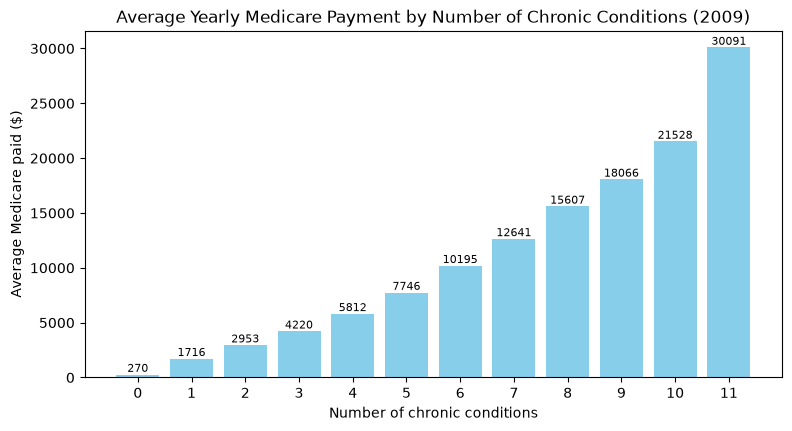

In [5]:
plt.figure(figsize=(9, 4.5))
bars = plt.bar(chronic_cost['chronic_conditions'], chronic_cost['avg_medicare_paid'], color='skyblue')
plt.bar_label(bars, fmt='%.0f', fontsize=8)

plt.xlabel('Number of chronic conditions')
plt.ylabel('Average Medicare paid ($)')
plt.title('Average Yearly Medicare Payment by Number of Chronic Conditions (2009)')
plt.xticks(range(0, 12))

plt.show()

The average payment goes up with every extra condition, from about 270 dollars a year with none of the conditions to about 30,091 dollars with all 11.

**Diabetic vs non-diabetic beneficiaries**

In [6]:
diabetic = pd.read_sql("""
SELECT
    CASE
        WHEN sp_diabetes = 1 THEN 'Diabetic'
        ELSE 'Not diabetic'
    END AS group_name,
    ROUND(AVG(medreimb_ip), 2) AS inpatient,
    ROUND(AVG(medreimb_op), 2) AS outpatient,
    ROUND(AVG(medreimb_car), 2) AS physician
FROM synpuf.beneficiary_2009
GROUP BY group_name
""", engine)
diabetic = diabetic.set_index('group_name')
diabetic

,inpatient,outpatient,physician
group_name,,,
Diabetic,4199.56,1372.07,2335.96
Not diabetic,755.45,339.37,625.28


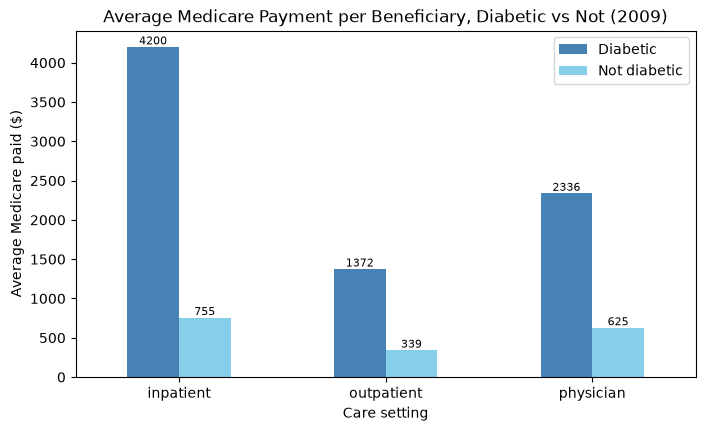

In [7]:
ax = diabetic.T.plot(kind='bar', figsize=(8, 4.5), color=['steelblue', 'skyblue'])

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=8)

plt.xlabel('Care setting')
plt.ylabel('Average Medicare paid ($)')
plt.title('Average Medicare Payment per Beneficiary, Diabetic vs Not (2009)')
plt.xticks(rotation=0)
plt.legend(title='')

plt.show()

Diabetic beneficiaries cost more in every setting. The biggest gap is inpatient care: about 4,200 dollars a year against 755.

**How concentrated is spending**

In [8]:
spending_bands = pd.read_sql("""
WITH BeneficiarySpend AS (
    SELECT
        medreimb_ip + medreimb_op + medreimb_car AS total_paid
    FROM synpuf.beneficiary_2009
)
SELECT
    CASE
        WHEN total_paid <= 0 THEN '0 or less'
        WHEN total_paid < 1000 THEN 'Under 1K'
        WHEN total_paid < 10000 THEN '1K-10K'
        WHEN total_paid < 50000 THEN '10K-50K'
        ELSE '50K+'
    END AS spending_band,
    COUNT(*) AS beneficiaries,
    SUM(total_paid) AS medicare_paid
FROM BeneficiarySpend
GROUP BY spending_band
ORDER BY MIN(total_paid)
""", engine)

spending_bands['pct_of_people'] = (spending_bands['beneficiaries'] / spending_bands['beneficiaries'].sum() * 100).round(1)
spending_bands['pct_of_spending'] = (spending_bands['medicare_paid'] / spending_bands['medicare_paid'].sum() * 100).round(1)
spending_bands['pct_of_spending'] = spending_bands['pct_of_spending'].clip(lower=0)  # the '0 or less' band has a small negative total
spending_bands

,spending_band,beneficiaries,medicare_paid,pct_of_people,pct_of_spending
0,0 or less,22604,-1430.0,19.7,-0.0
1,Under 1K,24399,10274610.0,21.3,2.1
2,1K-10K,54646,188462990.0,47.7,38.3
3,10K-50K,12038,237078150.0,10.5,48.2
4,50K+,851,56401060.0,0.7,11.5


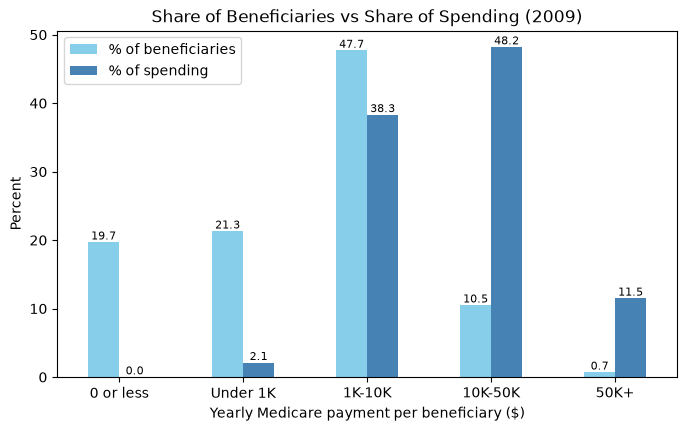

In [9]:
ax = spending_bands.set_index('spending_band')[['pct_of_people', 'pct_of_spending']].plot(kind='bar', figsize=(8, 4.5), color=['skyblue', 'steelblue'])

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', fontsize=8)

plt.xlabel('Yearly Medicare payment per beneficiary ($)')
plt.ylabel('Percent')
plt.title('Share of Beneficiaries vs Share of Spending (2009)')
plt.xticks(rotation=0)
plt.legend(['% of beneficiaries', '% of spending'])

plt.show()

About 11% of people (the two highest bands) account for about 60% of the money, while about 20% cost nothing that year.

**Monthly hospital admissions**

In [10]:
monthly = pd.read_sql("""
SELECT
    TO_CHAR(clm_from_dt, 'YYYY-MM') AS month,
    COUNT(*) AS admissions
FROM synpuf.inpatient_claims
WHERE clm_from_dt >= '2008-01-01'
GROUP BY month
ORDER BY month
""", engine)
monthly['month'] = pd.to_datetime(monthly['month'])
monthly.head()

,month,admissions
0,2008-01-01,1535
1,2008-02-01,1804
2,2008-03-01,2301
3,2008-04-01,2315
4,2008-05-01,2587


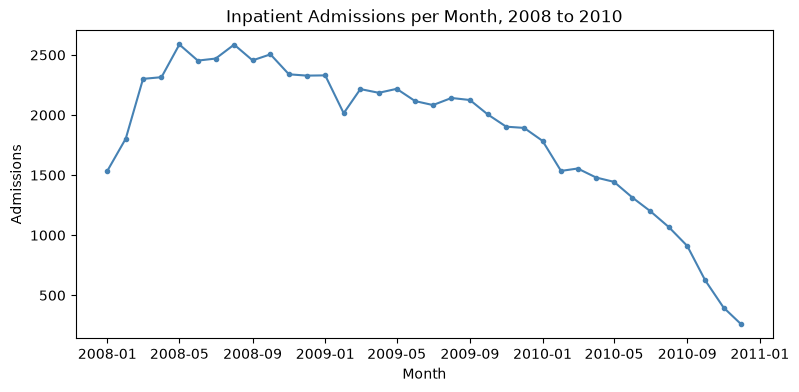

In [11]:
plt.figure(figsize=(9, 4))
plt.plot(monthly['month'], monthly['admissions'], color='steelblue', marker='o', markersize=3)

plt.xlabel('Month')
plt.ylabel('Admissions')
plt.title('Inpatient Admissions per Month, 2008 to 2010')

plt.show()

Admissions stay around 2,000 to 2,500 a month through 2008 and 2009, then fall during 2010. CMS built the sample this way, so this drop is not a real Medicare trend.